# Laminar model comparison with FEM, BEM, and single-shell forward models

We'll simulate a 20 Hz signal at each of the 11 cortical depths in sub-104 using a finite element model (FEM). Can we recover the simulated depth with a FEM, a boundary element model (BEM) or a single-shell model? We'll fit the three models to the same noisy recording at each depth, using the free-energy comparison from [Tutorial 02](https://danclab.github.io/laMEG/auto_tutorials/tutorial_02_model_comparison_free_energy.html) and [Bonaiuto et al. (2018)](https://doi.org/10.1016/j.neuroimage.2017.11.068).

## Setting up the simulation

Run this notebook from the laMEG `tutorials` directory with the [test data](https://osf.io/x4zd3/download) in `../test_data`. Install the FEM extra with `pip install -e '.[fem]'` from the repository root and build the [DUNEuro Python bindings](https://www.medizin.uni-muenster.de/duneuro/startseite.html) for the notebook environment. The FEM also requires a [SimNIBS CHARM mesh](https://simnibs.github.io/simnibs/build/html/documentation/command_line/charm.html) for the same subject.

For this example, run `charm sub-104 ../fs/sub-104/mri/orig.nii --forcesform` once from `test_data/sub-104` in your SimNIBS environment. The qform is unset in this T1, so we use the sform that the notebook reads for its MRI coordinates. CHARM writes the mesh to `m2m_sub-104/sub-104.msh`. Inspect the segmentation in CHARM’s `results.html`. If you already have a CHARM mesh in this coordinate frame, set `charm_fname` below to its location.

In [1]:
import os
import shutil
import tempfile

# Check the optional FEM packages before starting the forward calculations.
import duneuropy
import meshio

import matplotlib.pyplot as plt
import mne
import nibabel as nib
import numpy as np
import spm_standalone
import matlab
from mne.transforms import Transform, apply_trans

from lameg.forward import ForwardOperator, compute_duneuro_forward, compute_mne_forward
from lameg.invert import attach_forward_operator, coregister
from lameg.laminar import model_comparison
from lameg.simulate import run_current_density_simulation
from lameg.surf import LayerSurfaceSet
from lameg.util import get_fiducial_coords
from lameg.viz import show_surface

subj_id = 'sub-104'
ses_id = 'ses-01'
test_dir = os.path.abspath('../test_data')
meg_dir = os.path.join(test_dir, subj_id, 'meg', ses_id)

# Use the same subject's MRI, cortical surfaces and recording for all three models.
surf_set = LayerSurfaceSet(subj_id, 11, subjects_dir=os.path.join(test_dir, 'fs'))
charm_fname = os.path.join(test_dir, subj_id, f'm2m_{subj_id}', f'{subj_id}.msh')
if not os.path.isfile(charm_fname):
    raise FileNotFoundError(f'Set charm_fname to the CHARM mesh for {subj_id}: {charm_fname}')

fid_coords = get_fiducial_coords(subj_id, os.path.join(test_dir, 'participants.tsv'))
data_base = f'spm-converted_autoreject-{subj_id}-{ses_id}-001-btn_trial-epo'
data_file = os.path.join(meg_dir, 'spm', data_base + '.mat')
fif_file = os.path.join(meg_dir, 'mne', f'autoreject-{subj_id}-{ses_id}-001-btn_trial-epo.fif')
info = mne.io.read_info(fif_file)
spm = spm_standalone.initialize()

    Read 5 compensation matrices


We'll work on a copy of the recording in a temporary directory.

In [2]:
tmp_dir = tempfile.mkdtemp()
base_fname = shutil.copy(data_file, tmp_dir)
shutil.copy(os.path.splitext(data_file)[0] + '.dat', tmp_dir)

'/home/bonaiuto/tmp/tmpysqzwnme/spm-converted_autoreject-sub-104-ses-01-001-btn_trial-epo.dat'

## Building the BEM forward model

SPM and MNE use different MRI coordinate systems. We'll put the skull, scalp and MRI fiducials in FreeSurfer surface RAS, then match the MRI fiducials to their measured positions in the MEG head frame.

In [3]:
# Both MRI transforms start at the same voxel coordinates.
voxel_to_ras = nib.load(os.path.join(surf_set.subj_dir, 'mri', 'orig.mgz')).header.get_vox2ras_tkr()
voxel_to_native = nib.load(os.path.join(surf_set.subj_dir, 'mri', 'orig.nii')).affine
native_to_ras = voxel_to_ras @ np.linalg.inv(voxel_to_native)

mri_fids = [fid_coords[key] for key in ('nas', 'lpa', 'rpa')]
mri_fids = apply_trans(native_to_ras, mri_fids) / 1000  # MNE uses metres.
dig = info.get_montage().get_positions()
head_fids = [dig[key] for key in ('nasion', 'lpa', 'rpa')]
trans = Transform('mri', 'head', mne.coreg.fit_matched_points(mri_fids, head_fids))

For the MEG forward model, we'll use a three-compartment BEM representing the brain, skull and scalp. The contours show the inner skull (red), outer skull (yellow) and scalp (orange) on the subject's MRI.

Creating the BEM geometry...
outer skin  CM is   2.26 -16.62  13.62 mm
outer skull CM is   2.20 -18.08  17.02 mm
inner skull CM is   2.40 -19.10  17.15 mm
Checking that surface outer skull is inside surface outer skin  ...
Checking that surface inner skull is inside surface outer skull ...
Nearest-neighbor searches will be significantly faster if scikit-learn is installed.
Checking distance between outer skin  and outer skull surfaces...
Minimum distance between the outer skin  and outer skull surfaces is approximately    7.2 mm
Nearest-neighbor searches will be significantly faster if scikit-learn is installed.
Checking distance between outer skull and inner skull surfaces...
Minimum distance between the outer skull and inner skull surfaces is approximately    1.4 mm
Surfaces passed the basic topology checks.
Complete.

Three-layer model surfaces loaded.
Computing the linear collocation solution...
    Matrix coefficients...
        outer skin  (2562) -> outer skin  (2562) ...
       

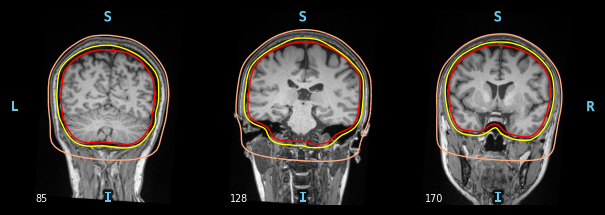

In [4]:
# Build the MNE subject in the temporary directory so the original anatomy is preserved.
bem_dir = os.path.join(tmp_dir, subj_id, 'bem')
mri_dir = os.path.join(tmp_dir, subj_id, 'mri')
os.makedirs(bem_dir)
os.makedirs(mri_dir)
shutil.copy(os.path.join(surf_set.subj_dir, 'mri', 'orig.mgz'), mri_dir)

# Use the three SPM boundaries at the same resolution.
boundaries = {
    'inner_skull': surf_set.load_head_mesh('iskull'),
    'outer_skull': surf_set.load_head_mesh('oskull'),
    'outer_skin': nib.load(os.path.join(surf_set.subj_dir, 'mri', 'origscalp_2562.surf.gii')),
}

for name, mesh in boundaries.items():
    vertices = apply_trans(native_to_ras, mesh.agg_data('pointset'))
    faces = mesh.agg_data('triangle')
    mne.write_surface(os.path.join(bem_dir, f'{name}.surf'), vertices, faces, overwrite=True)

model = mne.make_bem_model(
    subj_id,
    subjects_dir=tmp_dir,
    ico=None,
    conductivity=(0.3, 0.006, 0.3),  # brain, skull, scalp (S/m)
)

bem_solution = mne.make_bem_solution(model)

mne.viz.plot_bem(
    subject=subj_id, subjects_dir=tmp_dir, mri='orig.mgz',
    slices=[85, 128, 170], show=False,
)
plt.show()

Coregister the recording to the multilayer mesh.

In [5]:
# Coregister data to multilayer mesh
skull_fname = os.path.join(surf_set.subj_dir, 'mri', 'origiskull_2562.surf.gii')
coregister(
    fid_coords, 
    base_fname,
    surf_set,
    iskull_fname=skull_fname, 
    spm_instance=spm
)

SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )___/ )    (   Statistical Parametric Mapping           
(___/(__)  (_/\/\_)  SPM - https://www.fil.ion.ucl.ac.uk/spm/

Initialising batch system... done.


------------------------------------------------------------------------
27-Nov-2026 14:30:19 - Running job #1
------------------------------------------------------------------------
27-Nov-2026 14:30:19 - Running 'Head model specification'

SPM: spm_eeg_inv_mesh_ui                           14:30:20 - 27/11/2026
multilayer.11.ds.link_vector.fixed
undoing the G3BR balancing for the gradiometer definition
creating layout from cfg.grad
undoing the G3BR balancing for the gradiometer definition
creating layout for ctf275 system

SPM: spm_eeg_inv_forward                           14:31:41 - 27/11/2026
Completed                   

We'll use the BEM solution to compute the gain on each cortical surface. laMEG projects the lead fields onto the link vectors and keeps the vertices that MNE retained at every depth.

In [6]:
prepared = compute_mne_forward(
    surf_set, bem_solution, info, trans,
    reference=base_fname,
    output_dir=tmp_dir,
    allow_nominal_ctf_coils=True
)
bem = prepared.operator
surfaces = prepared.surfaces
print(f'{bem.n_columns:,} of {surf_set.get_vertices_per_layer():,} vertices retained per surface')

Sphere                : origin at (0.0 0.0 0.0) mm
              radius  : 95.0 mm
Source location file  : dict()
Assuming input in millimeters
Assuming input in MRI coordinates

Positions (in meters) and orientations
51091 sources
Source space          : <SourceSpaces: [<discrete, n_used=51091>] MRI (surface RAS) coords, ~3.1 MB>
MRI -> head transform : instance of Transform
Measurement data      : instance of Info
Conductor model   : instance of ConductorModel
Accurate field computations
Do computations in head coordinates
Free source orientations

Read 1 source spaces a total of 51091 active source locations

Coordinate transformation: MRI (surface RAS) -> head
     0.995616  0.056208 -0.074757      -0.56 mm
    -0.029827  0.948357  0.315801      19.70 mm
     0.088647 -0.312187  0.945876      33.88 mm
     0.000000  0.000000  0.000000       1.00

Read 303 MEG channels from info
Read 29 MEG compensation channels from info
5 compensation data sets in info
Setting up compensation data

[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.


    Found   593/38949 points outside using solid angles
    Total 46504/51091 points inside the surface
Interior check completed in 36743.5 ms
    4587 source space points omitted because they are outside the inner skull surface.

Checking surface interior status for 303 points...
    Found   0/303 points inside  an interior sphere of radius   82.9 mm
    Found 298/303 points outside an exterior sphere of radius  110.5 mm
    Found   5/  5 points outside using surface Qhull


[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:   36.6s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:   36.6s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.


    Found   0/  0 points outside using solid angles
    Total 0/303 points inside the surface
Interior check completed in 304.3 ms

Composing the field computation matrix...


[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.3s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.3s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.5s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.5s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.6s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.6s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.6s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.6s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.8s remaining:    0

... (81 outputs left out)

[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.4s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.4s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:   33.6s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:   33.6s finished



Finished.
    Write a source space...
    [done]
    1 source spaces written


/home/bonaiuto/miniconda3/envs/lameg_dev/lib/python3.7/site-packages/lameg/forward.py:576: UserWarning: Using 46504 of 51091 original cortical vertices at every depth after MNE preparation (pial: 4587, 0.900: 4078, 0.800: 3574, 0.700: 3035, 0.600: 2508, 0.500: 2028, 0.400: 1526, 0.300: 1131, 0.200: 841, 0.100: 626, white: 440). See /home/bonaiuto/tmp/tmpysqzwnme/mne-forward-a8bfzuf_/source_support.json.
  import_options, ForwardOperator.from_mne)


46,504 of 51,091 vertices retained per surface


## Building the FEM forward model

The CHARM mesh supplies the tissue compartments. The coregistered recording supplies the measured CTF coil positions and channel weights. DUNEuro computes the field for a unit dipole along each signed link vector. The FEM uses [SimNIBS tissue conductivities](https://simnibs.github.io/simnibs/build/html/documentation/conductivity.html) in S/m. We keep the cortical columns whose dipoles are in gray matter at every depth and use those same columns for all three models.

In [15]:
fem_prepared = compute_duneuro_forward(
    surfaces, charm_fname, reference=base_fname, output_dir=tmp_dir,
    n_jobs=2, verbose=True,
)
fem = fem_prepared.operator
bem = fem_prepared.restrict_operator(bem)
surfaces = fem_prepared.surfaces
layer_names = surfaces.get_layer_names()
n_layers = len(layer_names)

Reading CHARM mesh /home/bonaiuto/laMEG/test_data/sub-104/m2m_sub-104/sub-104.msh.

Locating 511,544 dipoles in 4,920,469 tetrahedra.
Checking 168,289 candidate dipoles with the DUNEuro element search before the pickup solve.
Solving 579 physical pickups for 133,672 dipoles with 2 DUNEuro workers.


[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.


volume_conductor.time_creating_grid = 144.85
volume_conductor.time_reordering_labels = 0.381999
volume_conductor.time = 145.236
degree = 1
element_type = tetrahedron
volume_conductor.time_creating_grid = 146.183
volume_conductor.time_reordering_labels = 0.384081
volume_conductor.time = 146.57
degree = 1
element_type = tetrahedron
=== matrix setup (max) 10.9657 s
=== matrix setup (max) 11.3138 s
Pickup fields complete. Applying channel weights.


[Parallel(n_jobs=2)]: Done   2 out of   2 | elapsed: 241.3min remaining:    0.0s
[Parallel(n_jobs=2)]: Done   2 out of   2 | elapsed: 241.3min finished
/home/bonaiuto/miniconda3/envs/lameg_dev/lib/python3.7/site-packages/ipykernel_launcher.py:3: UserWarning: Using 12181 of 51091 original cortical vertices at every depth after DUNEuro preparation (pial: 15335, 0.900: 10842, 0.800: 7404, 0.700: 5251, 0.600: 4119, 0.500: 3697, 0.400: 3850, 0.300: 5073, 0.200: 8184, 0.100: 13672, white: 22185). The native gray-matter check rejected 16 of the candidate dipoles. See /home/bonaiuto/tmp/tmpysqzwnme/duneuro-forward-4iyru93t/source_support.json.
  This is separate from the ipykernel package so we can avoid doing imports until


## Building the single-shell forward model

We'll compute the single-shell gain on the shared cortical surfaces for comparison.

In [16]:
coregister(
    fid_coords, base_fname, surfaces,
    forward_model_type='Single Shell', iskull_fname=skull_fname,
    viz=False, spm_instance=spm
)

# Ask SPM to compute the gain, then read it into laMEG.
modes_fname = os.path.join(tmp_dir, 'single_shell_modes.mat')
spm.spm_eeg_inv_prep_modes_xval(
    base_fname, matlab.double([]), modes_fname, 1.0, 0.0, nargout=0
)

single_shell = ForwardOperator.from_spm(
    base_fname, surfaces.get_mesh_path(), surfaces.get_layer_names(), allow_undefined_gain=True
)

models = [('FEM', fem), ('BEM', bem), ('Single shell', single_shell)]
print(f'All three models use {fem.n_columns:,} cortical vertices per layer.')

volume_conductor.time_creating_grid = 150.163
volume_conductor.time_reordering_labels = 0.400147
volume_conductor.time = 150.565
SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )___/ )    (   Statistical Parametric Mapping           
(___/(__)  (_/\/\_)  SPM - https://www.fil.ion.ucl.ac.uk/spm/



------------------------------------------------------------------------
27-Nov-2026 20:05:04 - Running job #1
------------------------------------------------------------------------
27-Nov-2026 20:05:04 - Running 'Head model specification'
multilayer.11.ds.link_vector.fixed

SPM: spm_eeg_inv_forward                           20:05:34 - 27/11/2026
Completed                               :          20:05:34 - 27/11/2026
27-Nov-2026 20:05:36 - Done    'Head model specification'
27-Nov-2026 20:05:36 - Done

Removed 0 bad channels, 274 

## Simulating a signal

We'll simulate one second of a 20 Hz sine wave with a dipole moment of 1 nA m.

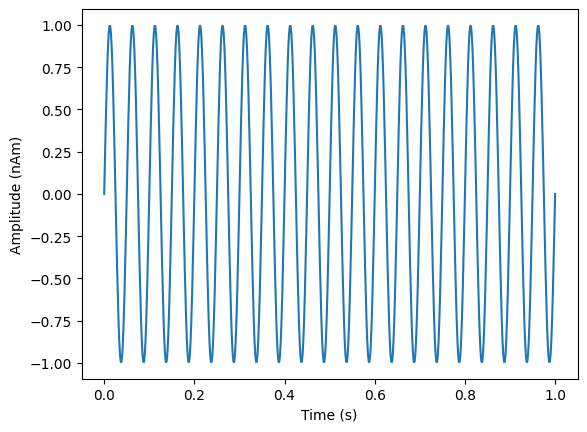

In [17]:
# Frequency of simulated sinusoid (Hz)
freq = 20
# Strength of simulated activity (nAm)
dipole_moment = 1
# Sampling rate (must match the data file)
s_rate = 600

# Generate 1s of a sine wave at a sampling rate of 600Hz (to match the data file)
time = np.linspace(0,1,s_rate+1)
sim_signal = np.sin(time*freq*2*np.pi).reshape(1,-1)

fig=plt.figure()
plt.plot(time,dipole_moment*sim_signal[0,:])
plt.xlabel('Time (s)')
plt.ylabel('Amplitude (nAm)')
plt.show()

We'll simulate near the original tutorial vertex (44523). If that column was excluded, we'll take the nearest usable pial vertex. The patch centre needs a defined orientation at every depth and neighbours on the retained surface.

In [18]:
pial = nib.load(surf_set.get_mesh_path('pial')).agg_data('pointset')
original_ids = fem_prepared.support.original_vertices
# These compact columns belong to a retained triangle, so they have neighbours for smoothing.
candidates = np.unique(fem.faces)
defined = fem.orientation_defined.reshape(n_layers, -1).all(axis=0)
candidates = candidates[defined[candidates]]
if not len(candidates):
    raise ValueError('No connected cortical column has a defined orientation at every depth.')

target_vertex = 44523
vertices = original_ids[candidates]
if target_vertex in vertices:
    sim_vertex = target_vertex
else:
    distance = np.linalg.norm(pial[vertices] - pial[target_vertex], axis=1)
    sim_vertex = vertices[np.argmin(distance)]
column = fem_prepared.support.map_indices([sim_vertex])[0]
print(f'Simulating at original vertex {sim_vertex}.')

# Centre the view on the selected pial vertex.
centre = pial[sim_vertex]
cam_view = [*(centre + [271, -11, -57]), *centre, 0.25, 0, 1]
plot = show_surface(surf_set, layer_name='pial', orientation='link_vector', fixed=True,
                    marker_vertices=sim_vertex, marker_size=5, camera_view=cam_view)

Simulating at original vertex 44283.


Output()

## Plotting the forward models

The first row shows the field at the sensors for a 1 nA m dipole on the white matter surface. The second row shows the signed difference between each pair of forward models.

Removing 5 compensators from info because not all compensation channels were picked.


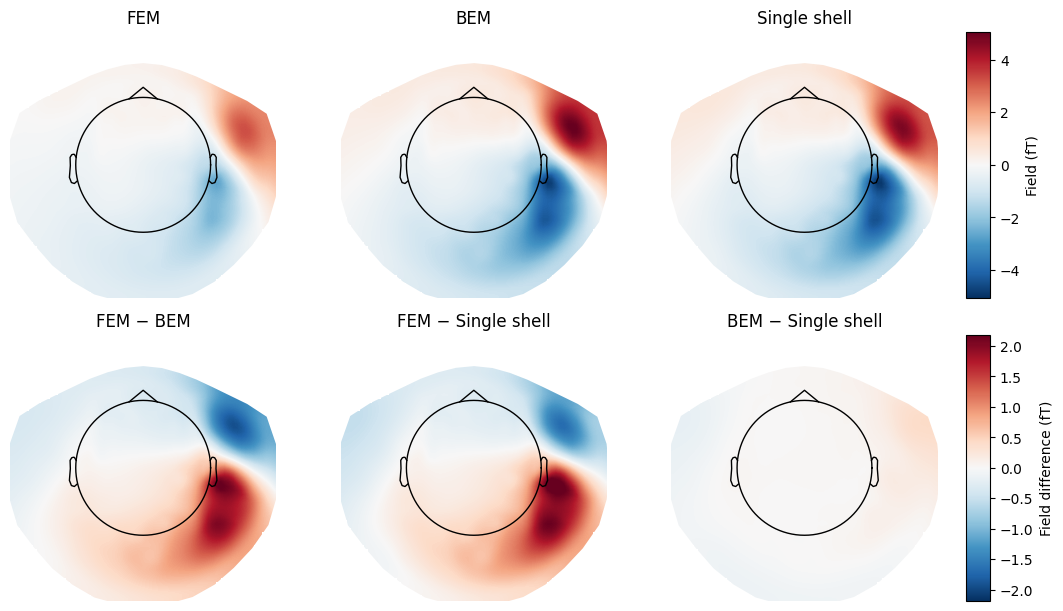

In [19]:
# Match the recording's channels before subtracting the sensor fields.
assert all(forward.channel_names == fem.channel_names and forward.channel_units == fem.channel_units
           for _, forward in models)
picks = mne.pick_channels(info.ch_names, list(fem.channel_names), ordered=True)
sensor_info = mne.pick_info(info, picks)
names = [name for name, _ in models]
fields = [forward.layer('white').gain[:, column] for _, forward in models]
pairs = [(0, 1), (0, 2), (1, 2)]
differences = [fields[i] - fields[j] for i, j in pairs]
pair_names = [f'{names[i]} − {names[j]}' for i, j in pairs]

fig, axes = plt.subplots(2, 3, figsize=(11, 6), constrained_layout=True)
for row, maps, titles, label in [(axes[0], fields, names, 'Field (fT)'),
                                 (axes[1], differences, pair_names, 'Field difference (fT)')]:
    # A shared scale within each row makes the amplitudes directly comparable.
    limit = np.max(np.abs(maps)) or 1.
    for ax, field, title in zip(row, maps, titles):
        im, _ = mne.viz.plot_topomap(
            field, sensor_info, ch_type='mag', axes=ax, show=False, cmap='RdBu_r',
            vlim=(-limit, limit), contours=0, sensors=False
        )
        ax.set_title(title)
    fig.colorbar(im, ax=row, label=label)
plt.show()

## Simulating each layer with FEM

We'll attach the multilayer FEM gain to the recording, which is already registered to the shared mesh. For each simulated depth we'll then fit all 11 candidate layers with each forward model, using one noisy recording for the three fits.

In [20]:
attach_forward_operator(base_fname, fem, 0, spm, surfaces.get_mesh_path())

sim_patch_size = 5  # mm
SNR = -5            # dB
all_layerF = {name: np.empty((n_layers, n_layers)) for name, _ in models}

for l, layer in enumerate(layer_names):
    print(f'Simulating on layer {l} ({layer})')
    vertex = surfaces.get_multilayer_vertex(layer, column)
    sim_fname = run_current_density_simulation(
        base_fname, f'fem_{sim_vertex}_{l}_', vertex, sim_signal, dipole_moment,
        sim_patch_size, SNR, viz=False, spm_instance=spm
    )

    for name, forward in models:
        # Each fit updates its SPM header. Copy the same signal and noise into a fresh directory.
        with tempfile.TemporaryDirectory(dir=tmp_dir) as fit_dir:
            fit_fname = shutil.copy(sim_fname, fit_dir)
            shutil.copy(os.path.splitext(sim_fname)[0] + '.dat', fit_dir)
            F, _ = model_comparison(
                fid_coords, fit_fname, surfaces, forward_operator=forward,
                forward_kwargs={'iskull_fname': skull_fname},
                # Keep the same sensor space for every gain when comparing free energies.
                invert_kwargs={'patch_size': 5, 'n_temp_modes': 4, 'n_spatial_modes': 'all'},
                viz=False, spm_instance=spm
            )
            all_layerF[name][l, :] = F

SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )___/ )    (   Statistical Parametric Mapping           
(___/(__)  (_/\/\_)  SPM - https://www.fil.ion.ucl.ac.uk/spm/

Simulating on layer 0 (pial)
SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )___/ )    (   Statistical Parametric Mapping           
(___/(__)  (_/\/\_)  SPM - https://www.fil.ion.ucl.ac.uk/spm/

Simulating data on MEG channels only
Using closest mesh vertices to the specified coordinates
Furthest distance from dipole location to mesh 0.00 mm

ans =

    'm'

SIMULATING CURRENT DISTRIBUTIONS ON MESH
Computing Gain Matrix:  - done
Saving prior in directory /home/bonaiuto/tmp/tmpysqzwnme/simprior_fem_442

Removed 0 bad channels, 274 total channels

Taking random selections of 0.00 percent of channels
Using maximum of 274 spatial modes

Preparing modes file  block 1 of 1 for 274 training and 0 test chans

 saving spatial mode file /home/bonaiuto/tmp/tmpysqzwnme/tmpepos4_66/fem_44283_0_spm-converted_autoreject-sub-104-ses-01-001-btn_trial-epo_testmodes.mat
SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )___/ )    (   Statistical Parametric Mapping           
(___/(__)  (_/\/\_)  SPM - https://www.fil.ion.ucl.ac.uk/spm/



------------------------------------------------------------------------
27-Nov-2026 20:08:54 - Running job #1
------------------------------------------------------------------------
27-Nov-2026 20:08:54 - Running 'Source inversion, iterative'
Loading spatial modes from file
Using testchans defined in spatial 

0.700.ds.link_vector.fixed

SPM: spm_eeg_inv_forward                           20:10:18 - 27/11/2026
Completed                               :          20:10:19 - 27/11/2026
27-Nov-2026 20:10:20 - Done    'Head model specification'
27-Nov-2026 20:10:20 - Done

SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )___/ )    (   Statistical Parametric Mapping           
(___/(__)  (_/\/\_)  SPM - https://www.fil.ion.ucl.ac.uk/spm/

Smoothing /home/bonaiuto/tmp/tmpysqzwnme/duneuro-forward-4iyru93t/0.700.ds.link_vector.fixed.gii

smoothmeshname =

    '/home/bonaiuto/tmp/tmpysqzwnme/duneuro-forward-4iyru93t/FWHM5.00_0.700.ds.link_vector.fixed.mat'


 FWHM of 5.00 is approx 3.61 times vertex spacing

 Smoothing with fwhm 5.00 (1 of 1) this make take some time (~20mins per FWHM with parallel toolbox)

 Layer 1
Saving /home/bonaiuto/tmp/t

Inverting subject 1
  ReML Iteration 1                      :        ...3.104030e+04 [+4.12]
  ReML Iteration 2                      :        ...2.897007e+04 [+4.25]
  ReML Iteration 3                      :        ...2.511908e+04 [+4.38]
  ReML Iteration 4                      :        ...1.804247e+04 [+4.50]
  ReML Iteration 5                      :        ...8.398415e+03 [+4.62]
  ReML Iteration 6                      :        ...2.330843e-01 [+4.75]
  ReML Iteration 7                      :        ...9.271384e-04 [+4.88]
Percent variance explained 99.98 (43.49)
model evidences relative to maximum:

ans =

     0

27-Nov-2026 20:11:22 - Done    'Source inversion, iterative'
27-Nov-2026 20:11:22 - Done

SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )___/ )    (   Statistical Parametric Mapping           
(___/(__)  (_/\/\_

Loading spatial modes from file
Using testchans defined in spatial modes file

gainname =

    'lameg_gain_3dcd9de6e66a2aa3e7113af7b9d527d2aa91bdca1332b666292cf7d66bb76a2d.mat'

Checking leadfieldsReseting random number seed ! and then generating random patch centres 
patchiter 1/1
Checking leadfields
ans =

    0.1782    0.9791
    0.5931    0.1947

 - done

Found smoothfile /home/bonaiuto/tmp/tmpysqzwnme/duneuro-forward-4iyru93t/FWHM5.00_0.400.ds.link_vector.fixed.mat, not recomputing
 - done
Optimising and aligning spatial modes ...
Using pre-specified spatial modes
Using 274 spatial modesNumber of samples 601
Fixed number of temporal modes
Using 4 temporal modes, accounting for 43.50 percent average variance
NB smooth EBB algorithm !
Using 1 spatial source priors provided
  ReML Iteration 1                      :        ...3.104595e+04 [+4.12]
  ReML Iteration 2                      :        ...2.898004e+04 [+4.25]
  ReML Iteration 3                      :        ...2.513285e+04 [+

Smoothing /home/bonaiuto/tmp/tmpysqzwnme/duneuro-forward-4iyru93t/0.200.ds.link_vector.fixed.gii

smoothmeshname =

    '/home/bonaiuto/tmp/tmpysqzwnme/duneuro-forward-4iyru93t/FWHM5.00_0.200.ds.link_vector.fixed.mat'


 FWHM of 5.00 is approx 3.99 times vertex spacing

 Smoothing with fwhm 5.00 (1 of 1) this make take some time (~20mins per FWHM with parallel toolbox)

 Layer 1
Saving /home/bonaiuto/tmp/tmpysqzwnme/duneuro-forward-4iyru93t/FWHM5.00_0.200.ds.link_vector.fixed.mat
Removed 0 bad channels, 274 total channels

Taking random selections of 0.00 percent of channels
Using maximum of 274 spatial modes

Preparing modes file  block 1 of 1 for 274 training and 0 test chans

 saving spatial mode file /home/bonaiuto/tmp/tmpysqzwnme/tmpepos4_66/fem_44283_0_spm-converted_autoreject-sub-104-ses-01-001-btn_trial-epo_testmodes.mat
SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  

... (199 outputs left out)

Percent variance explained 99.97 (44.28)
model evidences relative to maximum:

ans =

     0

28-Nov-2026 00:23:56 - Done    'Source inversion, iterative'
28-Nov-2026 00:23:56 - Done

SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )___/ )    (   Statistical Parametric Mapping           
(___/(__)  (_/\/\_)  SPM - https://www.fil.ion.ucl.ac.uk/spm/



------------------------------------------------------------------------
28-Nov-2026 00:23:56 - Running job #1
------------------------------------------------------------------------
28-Nov-2026 00:23:56 - Running 'Head model specification'
0.500.ds.link_vector.fixed

SPM: spm_eeg_inv_forward                           00:24:25 - 28/11/2026
Completed                               :          00:24:25 - 28/11/2026
28-Nov-2026 00:24:26 - Done    'Head model specification'
28-Nov-202

Using 274 spatial modesNumber of samples 601
Fixed number of temporal modes
Using 4 temporal modes, accounting for 44.30 percent average variance
NB smooth EBB algorithm !
Using 1 spatial source priors provided
  ReML Iteration 1                      :        ...3.096937e+04 [+4.12]
  ReML Iteration 2                      :        ...2.878137e+04 [+4.25]
  ReML Iteration 3                      :        ...2.486105e+04 [+4.38]
  ReML Iteration 4                      :        ...1.798686e+04 [+4.50]
  ReML Iteration 5                      :        ...8.663073e+03 [+4.62]
  ReML Iteration 6                      :        ...2.619389e+01 [+4.75]
  ReML Iteration 7                      :        ...9.452798e-02 [+4.88]
  ReML Iteration 8                      :        ...9.013229e-04 [+5.00]
Inverting subject 1
  ReML Iteration 1                      :        ...3.096937e+04 [+4.12]
  ReML Iteration 2                      :        ...2.878137e+04 [+4.25]
  ReML Iteration 3                     



------------------------------------------------------------------------
28-Nov-2026 00:26:39 - Running job #1
------------------------------------------------------------------------
28-Nov-2026 00:26:39 - Running 'Source inversion, iterative'
Loading spatial modes from file
Using testchans defined in spatial modes file

gainname =

    'lameg_gain_8da5b5ac06f1536ae9a209f0dbf33199e2a6283497053acd9c95e8756f9af577.mat'

Checking leadfieldsReseting random number seed ! and then generating random patch centres 
patchiter 1/1
Checking leadfields
ans =

    0.1782    0.9791
    0.5931    0.1947

 - done

Found smoothfile /home/bonaiuto/tmp/tmpysqzwnme/duneuro-forward-4iyru93t/FWHM5.00_0.200.ds.link_vector.fixed.mat, not recomputing
 - done
Optimising and aligning spatial modes ...
Using pre-specified spatial modes
Using 274 spatial modesNumber of samples 601
Fixed number of temporal modes
Using 4 temporal modes, accounting for 44.30 percent average variance
NB smooth EBB algorithm !
Using

28-Nov-2026 00:27:59 - Done    'Head model specification'
28-Nov-2026 00:27:59 - Done

SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )___/ )    (   Statistical Parametric Mapping           
(___/(__)  (_/\/\_)  SPM - https://www.fil.ion.ucl.ac.uk/spm/

Smoothing /home/bonaiuto/tmp/tmpysqzwnme/duneuro-forward-4iyru93t/white.ds.link_vector.fixed.gii

smoothmeshname =

    '/home/bonaiuto/tmp/tmpysqzwnme/duneuro-forward-4iyru93t/FWHM5.00_white.ds.link_vector.fixed.mat'


Found smoothfile /home/bonaiuto/tmp/tmpysqzwnme/duneuro-forward-4iyru93t/FWHM5.00_white.ds.link_vector.fixed.mat, not recomputing
Removed 0 bad channels, 274 total channels

Taking random selections of 0.00 percent of channels
Using maximum of 274 spatial modes

Preparing modes file  block 1 of 1 for 274 training and 0 test chans

 saving spatial mode file /hom

## Comparing the layer estimates

For each forward model, plot free energy relative to the worst layer for that simulation. The dashed line shows perfect recovery of simulated depth (0 is pial, 10 is white matter).

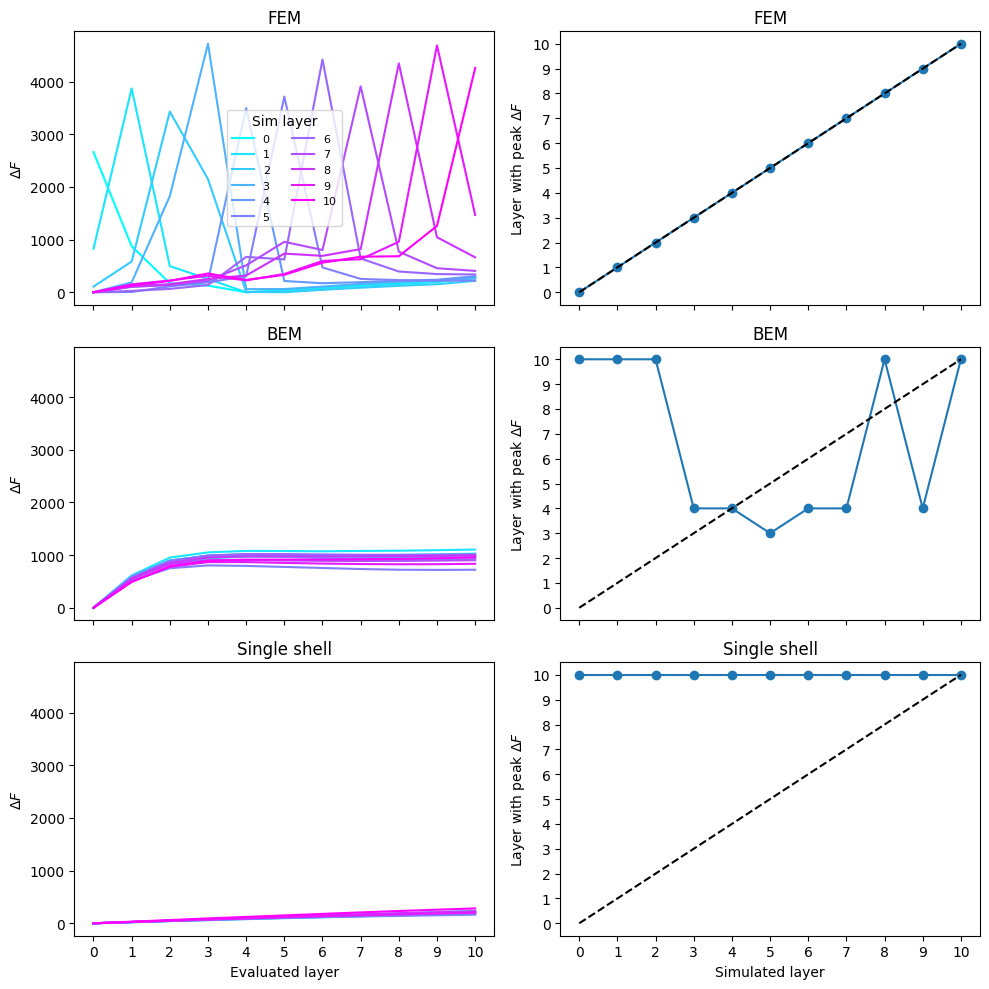

In [21]:
layers = np.arange(n_layers)
col_r = plt.cm.cool(np.linspace(0, 1, n_layers))

fig, axes = plt.subplots(len(models), 2, figsize=(10, 10), sharex='col', sharey='col')

for row, (name, _) in enumerate(models):
    F = all_layerF[name]
    ax_curves, ax_peaks = axes[row]

    # Each colored line is one simulated depth.
    for l in layers:
        ax_curves.plot(layers, F[l] - F[l].min(), color=col_r[l], label=str(l))
    ax_curves.set_title(name)
    ax_curves.set_ylabel(r'$\Delta F$')

    # For each simulation, find the evaluated layer with the highest free energy.
    ax_peaks.plot(layers, np.argmax(F, axis=1), 'o-')
    ax_peaks.plot([0, n_layers - 1], [0, n_layers - 1], 'k--')
    ax_peaks.set_title(name)
    ax_peaks.set_ylabel(r'Layer with peak $\Delta F$')
    ax_peaks.set_yticks(layers)

axes[0, 0].legend(title='Sim layer', ncol=2, fontsize=8)
axes[-1, 0].set_xlabel('Evaluated layer')
axes[-1, 1].set_xlabel('Simulated layer')
for ax in axes[-1]:
    ax.set_xticks(layers)

plt.tight_layout()
plt.show()

To compare evidence between forward models as well as layers, we'll use a common zero for each simulated recording. Each column is relative to the lowest free energy across all three solvers and all 11 candidate layers. The crosses mark each solver's best-fitting depth.

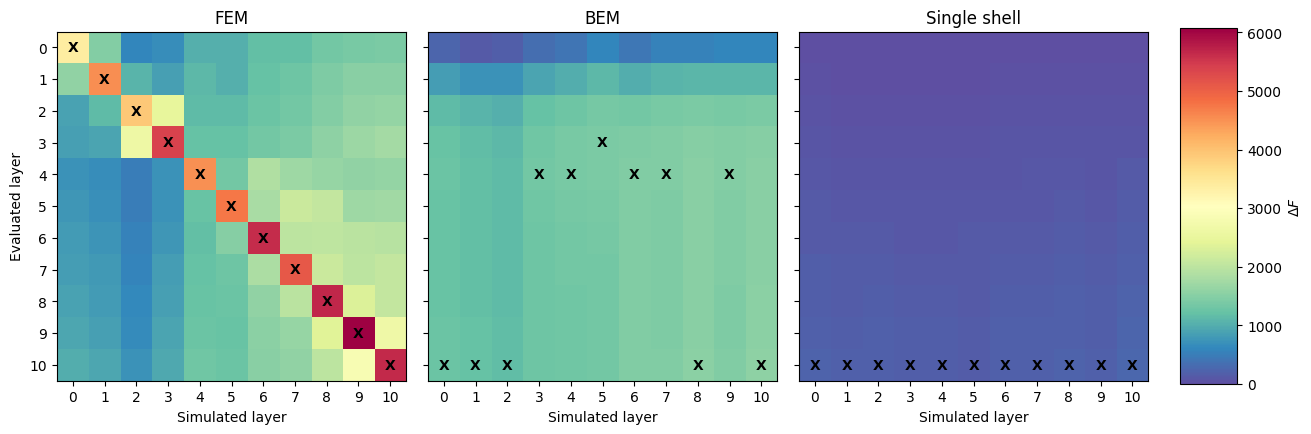

In [22]:
# The three axes of F index forward model, simulated layer and evaluated layer.
F = np.stack([all_layerF[name] for name, _ in models])
relative_F = F - F.min(axis=(0, 2), keepdims=True)

fig, axes = plt.subplots(1, len(models), figsize=(13, 4), sharey=True, constrained_layout=True)
for ax, (name, _), values in zip(axes, models, relative_F):
    im = ax.imshow(values.T, cmap='Spectral_r', vmin=0, vmax=relative_F.max(),
                   interpolation='nearest')
    for l, peak in enumerate(np.argmax(values, axis=1)):
        ax.text(l, peak, 'X', ha='center', va='center', weight='bold')
    ax.set_title(name)
    ax.set_xlabel('Simulated layer')
    ax.set_xticks(layers)
    ax.set_yticks(layers)
axes[0].set_ylabel('Evaluated layer')
fig.colorbar(im, ax=axes, label=r'$\Delta F$')
plt.show()

Here FEM generated the data. The results show how changing the forward model affects depth recovery for this source location and SNR.

We'll close SPM and remove the temporary files when we're finished.

In [ ]:
spm.terminate()

# Delete simulation files
shutil.rmtree(tmp_dir)